In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print(np.__version__, pd.__version__)

2.4.6 2.2.3


In [2]:
arr = np.array([10, 20, 30, 40, 50])
print(arr, arr.dtype, arr.shape, arr.ndim)
print(arr * 2)
print(arr + 5)

[10 20 30 40 50] int64 (5,) 1
[ 20  40  60  80 100]
[15 25 35 45 55]


In [3]:
rng = np.random.default_rng(42)
data = rng.normal(loc=50, scale=10, size=1000)
print(data[:10])
print(data.mean(), data.std(), data.min(), data.max())

[53.0471708  39.60015894 57.50451196 59.40564716 30.48964811 36.97820493
 51.27840403 46.83757408 49.83198842 41.46956072]
49.711084490040534 9.88722355396508 13.515871747852167 81.78853679367535


In [4]:
df = pd.DataFrame({
    'value': data,
    'group': rng.choice(['A', 'B', 'C'], size=1000)
})
print(df.head())
print(df.info())
print(df.describe())

       value group
0  53.047171     A
1  39.600159     B
2  57.504512     B
3  59.405647     B
4  30.489648     C
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   1000 non-null   float64
 1   group   1000 non-null   object 
dtypes: float64(1), object(1)
memory usage: 15.8+ KB
None
             value
count  1000.000000
mean     49.711084
std       9.892171
min      13.515872
25%      43.036871
50%      50.061779
75%      55.898867
max      81.788537


In [5]:
high = df[df['value'] > 60]
print(len(high))

grouped = df.groupby('group')['value'].agg(['count', 'mean', 'std'])
print(grouped)

grouped_flat = df.groupby('group', as_index=False)['value'].mean()
print(grouped_flat)

141
       count       mean        std
group                             
A        338  49.093216   9.794565
B        332  50.211463   9.752646
C        330  49.840521  10.124925
  group      value
0     A  49.093216
1     B  50.211463
2     C  49.840521


In [6]:
df.loc[df.sample(30, random_state=1).index, 'value'] = np.nan
print(df['value'].isna().sum())

df['value_filled'] = df['value'].fillna(df['value'].median())
df['value_dropped'] = df['value']
print(df['value_filled'].isna().sum())

30
0


In [7]:
df['value_sq'] = df['value_filled'] ** 2
df['is_high'] = df['value_filled'] > 60
print(df[['value_filled', 'value_sq', 'is_high']].head())

   value_filled     value_sq  is_high
0     53.047171  2814.002330    False
1     39.600159  1568.172588    False
2     57.504512  3306.768896    False
3     59.405647  3529.030915    False
4     30.489648   929.618642    False


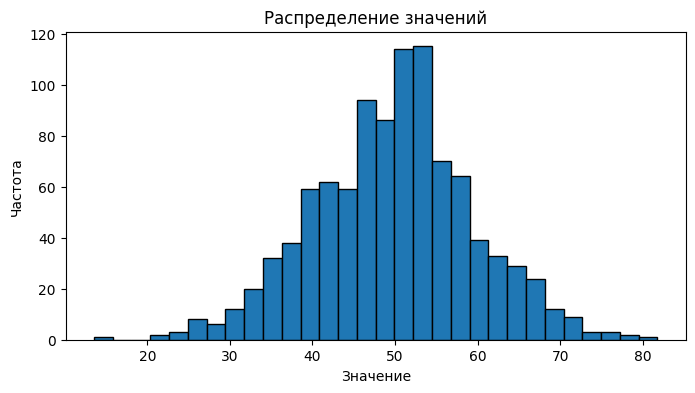

In [8]:
plt.figure(figsize=(8, 4))
plt.hist(df['value_filled'], bins=30, edgecolor='black')
plt.xlabel('Значение')
plt.ylabel('Частота')
plt.title('Распределение значений')
plt.show()

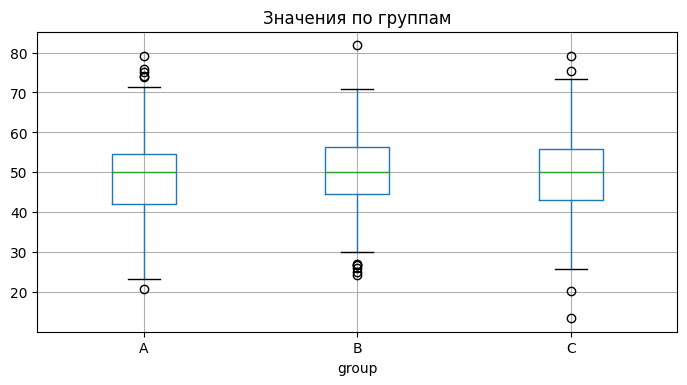

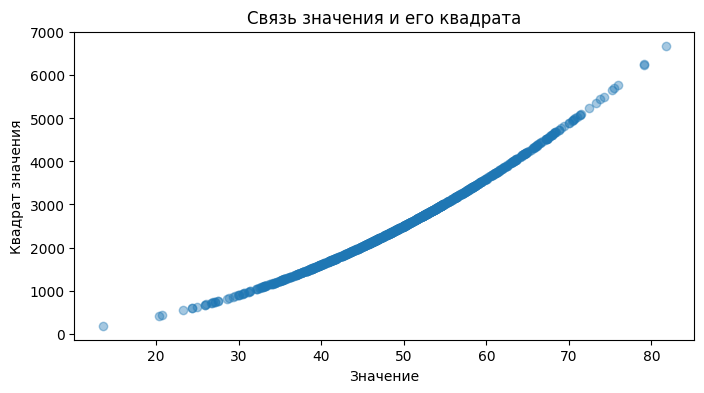

In [9]:
df.boxplot(column='value_filled', by='group', figsize=(8, 4))
plt.title('Значения по группам')
plt.suptitle('')
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(df['value_filled'], df['value_sq'], alpha=0.4)
plt.xlabel('Значение')
plt.ylabel('Квадрат значения')
plt.title('Связь значения и его квадрата')
plt.show()

In [10]:
df.to_csv('result.csv', index=False)
from google.colab import files
files.download('result.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>